# Step 9: Improving the within-subject EEGNet: beating the baseline paper honestly

**Goal:** the same network as the baseline paper (Nzakuna et al. 2025, EEGNet on BCI IV-2a, train session T → test session E),
but higher accuracy **without using any test labels**, and then fewer wrong wheelchair commands.

**Protocol (fixed in advance):**
- Every choice is made on **session T only**: 6-fold leave-one-run-out CV (each fold holds out one run of 48 trials).
- A change is kept only if it improves the T-CV accuracy by **≥ +0.5 points**.
- Session E is scored **once**, after all choices are fixed.

| Part | What | Code |
|---|---|---|
| 1 | Screening of 6 single ideas vs our EA EEGNet (BASE) | `experiments/run_improve.py`, `overnight_improve.py` |
| 1.6 | 15-model ensemble, MC dropout; rejection rerun | `experiments/run_ens.py`, `overnight_ens.py` |
| A1–A3 | Honest LEMC combination, fusion with Mam's classifier, the paper's own protocol | `experiments/run_lemc.py` |

In [1]:
import json, warnings
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent
FIG = ROOT / "results" / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
SUBJ = [f"A0{i}" for i in range(1, 10)]
CV = json.loads((ROOT / "results" / "improve" / "cv_summary.json").read_text())
ENS = json.loads((ROOT / "results" / "stageB_aug" / "summary.json").read_text())
LEMC = json.loads((ROOT / "results" / "lemc" / "summary.json").read_text())
for f in ["overnight_status_improve.txt", "overnight_status_ens.txt"]:
    print(f, "->", (ROOT / "results" / f).read_text().strip().splitlines()[-1])

overnight_status_improve.txt -> [2026-11-17 02:28:22] ALL DONE - results in results/improve/cv_summary.md and t2e_summary.md
overnight_status_ens.txt -> [2026-11-19 02:17:34] ALL DONE - results in results/stageB_aug/summary.md


## 1. Screening on session T (Part 1)

| Idea | What it changes |
|---|---|
| FTDB | FT-DropBlock instead of dropout (the paper's regulariser) |
| PREPD | the paper's preprocessing (no band-pass, −0.5–4 s, exponential moving standardisation) |
| AUGSR | segmentation & recombination: half the trials of each epoch rebuilt from 8 time segments of same-class trials |
| AUGNS | noise, amplitude scaling and time shift |
| RECIPE | label smoothing 0.1 + cosine learning rate |
| CLEAN | expert-marked artifact trials removed from training only |

One seed per idea, 400 epochs, accuracy read every 10 epochs; the epoch count is taken from the smoothed mean curve.

,best epoch,T-CV acc %,vs BASE,subjects better,Wilcoxon p,kept
AUGSR,290,75.15,2.91,8/9,0.008,True
BASE,290,72.25,0.0,0/9,None,False
AUGNS,180,71.86,-0.39,5/9,0.82,False
RECIPE,370,71.77,-0.48,3/9,0.398,False
CLEAN,390,70.25,-1.99,2/9,0.027,False
FTDB,230,69.43,-2.82,1/9,0.008,False
PREPD,400,67.04,-5.21,3/9,0.359,False


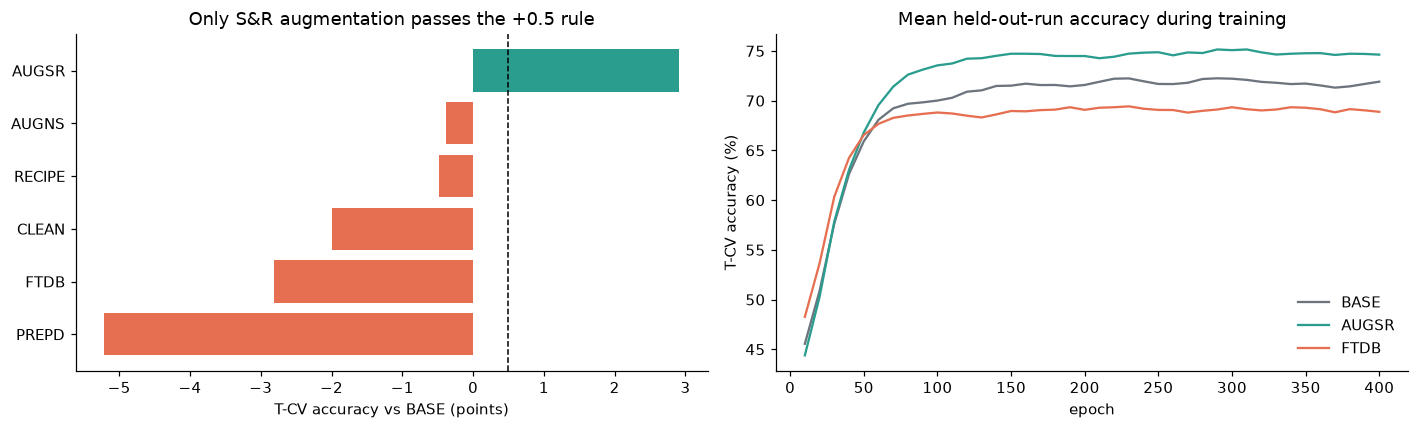

In [2]:
order = sorted(CV, key=lambda v: -CV[v]["cv_acc"])
tab = pd.DataFrame({v: {"best epoch": CV[v]["best_epoch"], "T-CV acc %": round(100 * CV[v]["cv_acc"], 2),
                        "vs BASE": round(100 * CV[v]["delta"], 2), "subjects better": f'{CV[v]["subjects_better"]}/9',
                        "Wilcoxon p": round(CV[v]["wilcoxon_p"], 3) if v != "BASE" else None, "kept": CV[v]["keep"]} for v in order}).T
display(tab)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
d = [100 * CV[v]["delta"] for v in order if v != "BASE"]
ax[0].barh([v for v in order if v != "BASE"], d, color=["#2a9d8f" if x >= 0.5 else "#e76f51" if x < 0 else "#adb5bd" for x in d])
ax[0].axvline(0.5, ls="--", c="k", lw=1); ax[0].invert_yaxis()
ax[0].set_xlabel("T-CV accuracy vs BASE (points)"); ax[0].set_title("Only S&R augmentation passes the +0.5 rule")
ep = np.arange(1, len(CV["BASE"]["curve"]) + 1) * 10
for v, c in [("BASE", "#6c757d"), ("AUGSR", "#2a9d8f"), ("FTDB", "#e76f51")]:
    ax[1].plot(ep, 100 * np.array(CV[v]["curve"]), label=v, c=c)
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("T-CV accuracy (%)"); ax[1].set_title("Mean held-out-run accuracy during training"); ax[1].legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG / "09_screening.png", bbox_inches="tight"); plt.show()

**Reading:** S&R augmentation is the only idea that helps (+2.9 points, 8/9 subjects, p = 0.008). The paper's own
ingredients (FT-DropBlock, its preprocessing) **hurt** on our pipeline (−2.8 and −5.2): they were designed for their
setting without Euclidean Alignment and band-pass filtering. Removing artifact trials from training also hurts (−2.0): with
only 288 trials per subject, every trial counts. The best epoch for S&R is 290 of 400, so the cap was not limiting.

## 2. Combination rule, chosen on session T (Part 1.6 and A1–A2)

All candidates use the same S&R EEGNet. T-CV numbers use a 5-model ensemble; the parts fitted on data are cross-fitted
(temperatures on the other 5 runs, the weighting network on the other 8 subjects), so none is scored on its own fitting data.

In [3]:
r = ENS["rule_on_T_cv"]
a1, a2 = LEMC["A1_T_cv"], LEMC["A2_T_cv"]
rows = [("plain mean", r["ensemble5"]["AUGSR"], "baseline"),
        ("MC dropout (50 passes)", r["ensemble5"]["AUGSR_MC"], "no (−0.12)"),
        ("per-model temperature", a1["acc"]["TEMP"], "–"),
        ("temperature + weighting network (honest LEMC)", a1["acc"]["LEMC"], f"yes (+{100 * (a1['acc']['LEMC'] - a1['acc']['PLAIN']):.2f})"),
        (f"LEMC + Mam's classifier (weight {a2['kept_weight']})", a2["acc_by_weight"][str(a2["kept_weight"])] if str(a2["kept_weight"]) in a2["acc_by_weight"] else a2["acc_by_weight"][a2["kept_weight"]],
         f"yes (+{100 * (a2['acc_by_weight'][str(a2['kept_weight'])] - a2['acc_by_weight']['0.0']):.2f})")]
display(pd.DataFrame(rows, columns=["rule", "T-CV acc", "kept"]).assign(**{"T-CV acc": lambda d: (100 * d["T-CV acc"]).round(2)}))

,rule,T-CV acc,kept
0,plain mean,78.82,baseline
1,MC dropout (50 passes),78.70,no (−0.12)
2,per-model temperature,79.24,–
3,temperature + weighting network (honest LEMC),79.48,yes (+0.66)
4,LEMC + Mam's classifier (weight 0.1),79.98,yes (+0.50)


## 3. Session E (scored once)

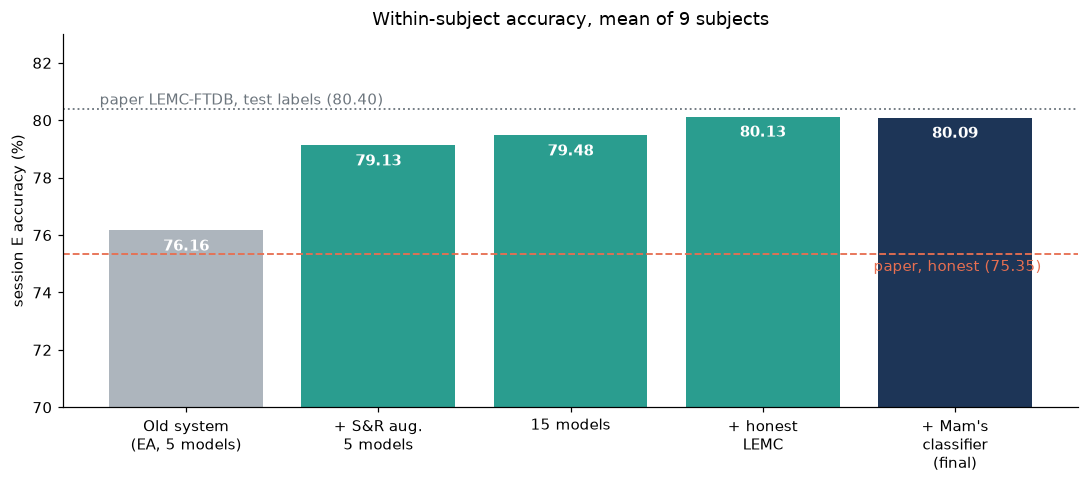

,all E trials (offline EA),first 48 trials (online EA)
"S&R, 5 models",79.13,76.93
"S&R, 15 models",79.48,77.74
+ honest LEMC,80.13,78.28
+ Mam's classifier (final),80.09,78.24


In [4]:
E = ENS["session_E"]; L = LEMC["session_E"]
steps = [("Old system\n(EA, 5 models)", 76.16),
         ("+ S&R aug.\n5 models", 100 * E["AUGSR|5|offline"]["ensemble"]),
         ("15 models", 100 * E["AUGSR|15|offline"]["ensemble"]),
         ("+ honest\nLEMC", 100 * L["offline"]["LEMC"]["mean"]),
         ("+ Mam's\nclassifier\n(final)", 100 * L["offline"]["FUSED_chosen"]["mean"])]
fig, ax = plt.subplots(figsize=(10, 4.5))
b = ax.bar([s for s, _ in steps], [v for _, v in steps], color=["#adb5bd"] + ["#2a9d8f"] * 3 + ["#1d3557"])
for x, (_, v) in zip(b, steps):
    ax.text(x.get_x() + x.get_width() / 2, v - 0.7, f"{v:.2f}", ha="center", color="white", fontweight="bold")
ax.axhline(75.35, ls="--", c="#e76f51", lw=1.2); ax.text(4.45, 74.75, "paper, honest (75.35)", ha="right", color="#e76f51")
ax.axhline(80.40, ls=":", c="#6c757d", lw=1.2); ax.text(-0.45, 80.55, "paper LEMC-FTDB, test labels (80.40)", ha="left", color="#6c757d")
ax.set_ylim(70, 83); ax.set_ylabel("session E accuracy (%)"); ax.set_title("Within-subject accuracy, mean of 9 subjects")
plt.tight_layout(); plt.savefig(FIG / "09_accuracy_steps.png", bbox_inches="tight"); plt.show()
tab = pd.DataFrame({
    "all E trials (offline EA)": [100 * E["AUGSR|5|offline"]["ensemble"], 100 * E["AUGSR|15|offline"]["ensemble"], 100 * L["offline"]["LEMC"]["mean"], 100 * L["offline"]["FUSED_chosen"]["mean"]],
    "first 48 trials (online EA)": [100 * E["AUGSR|5|online48"]["ensemble"], 100 * E["AUGSR|15|online48"]["ensemble"], 100 * L["online48"]["LEMC"]["mean"], 100 * L["online48"]["FUSED_chosen"]["mean"]],
}, index=["S&R, 5 models", "S&R, 15 models", "+ honest LEMC", "+ Mam's classifier (final)"]).round(2)
display(tab)

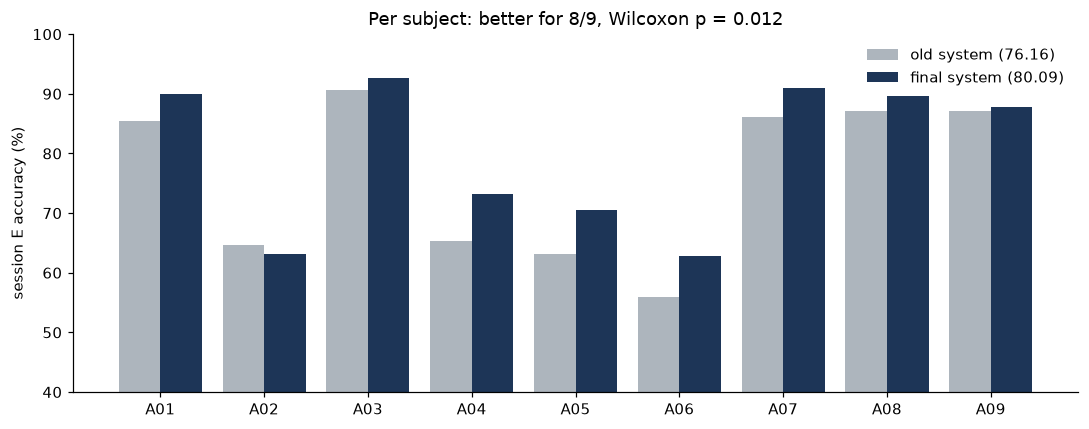

In [5]:
old = ENS["session_E"]["AUGSR|15|offline"]["vs_old"]
fin = L["offline"]["FUSED_chosen"]
oldps = {}
for f in (ROOT / "results" / "ea" / "within_t2e").glob("*.json"):
    j = json.loads(f.read_text()); oldps.setdefault(j["subject"], []).append((np.array(j["probs"]["offline"]), np.array(j["y"])))
old_s = {s: 100 * float((np.mean([p for p, _ in oldps[s]], 0).argmax(1) == oldps[s][0][1]).mean()) for s in SUBJ}
x = np.arange(9)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(x - 0.2, [old_s[s] for s in SUBJ], 0.4, label="old system (76.16)", color="#adb5bd")
ax.bar(x + 0.2, [100 * fin["per_subject"][s] for s in SUBJ], 0.4, label=f"final system ({100 * fin['mean']:.2f})", color="#1d3557")
ax.set_xticks(x, SUBJ); ax.set_ylabel("session E accuracy (%)"); ax.legend(frameon=False); ax.set_ylim(40, 100)
ax.set_title(f"Per subject: better for {fin['better_than_old']}/9, Wilcoxon p = {fin['p_vs_old']:.3f}")
plt.tight_layout(); plt.savefig(FIG / "09_per_subject.png", bbox_inches="tight"); plt.show()

**Reading:** the final system reaches **80.09%** on session E with no test labels used anywhere, +3.9 points over our
previous system (better for 8/9 subjects, p = 0.012) and +4.7 over the paper's honest 15-net ensemble (75.35%).
Most of the gain comes from S&R augmentation (+3.0) and the honest LEMC combination (+0.65). Mam's classifier was kept
by the pre-set rule on T-CV (+0.5) but changes E by −0.04: neutral. A02 (the only subject below the old system) stays the weakest.

## 4. Side comparison: the paper's own protocol (not honest)
In the paper's public code the per-model temperatures and the weighting network of LEMC-FTDB are fitted on the
**session-E labels** and then evaluated on the same session-E trials. Applying exactly that protocol to our 15 models shows
how much of their 80.40% comes from the protocol.

In [6]:
a3 = LEMC["A3_paper_protocol_E"]
display(pd.DataFrame({"accuracy %": [100 * a3["AUGSR"], 100 * a3["AUGSR_MC"], 80.40, 100 * L["offline"]["FUSED_chosen"]["mean"], 75.35]},
                     index=["ours, test-label protocol, deterministic", "ours, test-label protocol, MC dropout (= their recipe)",
                            "paper LEMC-FTDB (test-label protocol)", "ours, honest (final system)", "paper EMCD, honest (15 nets)"]).round(2))

,accuracy %
"ours, test-label protocol, deterministic",80.09
"ours, test-label protocol, MC dropout (= their recipe)",80.21
paper LEMC-FTDB (test-label protocol),80.40
"ours, honest (final system)",80.09
"paper EMCD, honest (15 nets)",75.35


**Reading:** under their protocol our model gets 80.2%, the same as their 80.4%. Under the honest protocol ours gets 80.1%
and theirs 75.4%. So with the same network, our pipeline (Euclidean Alignment, S&R augmentation, honest LEMC) closes
the gap that their method only closes by fitting on test labels. Wording for the report: "as far as we can see in their
public code, the LEMC temperatures and weights are fitted on the test session's labels."

## 5. Rejecting uncertain commands with the final system
Temperature and entropy threshold are fitted on the final system's own session-T CV outputs (one threshold for all
users), then applied to session E. Operating points as in Step 8: accept 80% of trials, and accepted commands ≥ 85% correct.

,EA reference,operating point,executed %,correct %,wrong per 100 trials
0,all E trials (offline EA),80% coverage,82.5,86.7,11.0
1,all E trials (offline EA),85% target,86.8,85.1,13.0
2,trials 49–288 (online EA),80% coverage,83.1,83.2,13.9
3,trials 49–288 (online EA),85% target,88.6,81.4,16.4


Calibration error after temperature scaling: 1.7% (raw 3.3%)


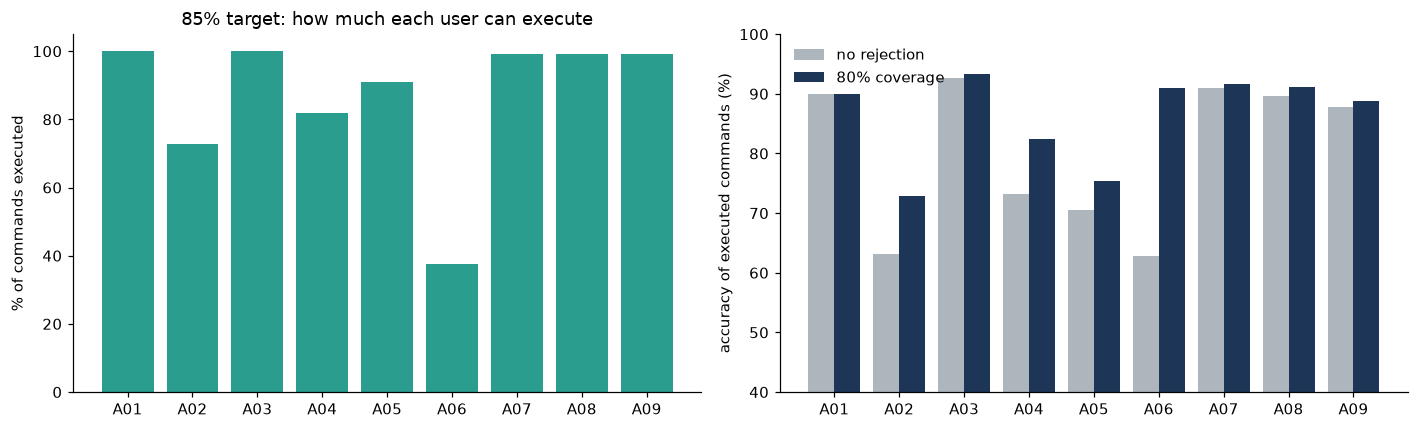

In [7]:
R = LEMC["rejection"]
rows = []
for name, lab in [("within", "all E trials (offline EA)"), ("within_online48", "trials 49–288 (online EA)")]:
    m = R[name]
    for op, opl in [("cov80", "80% coverage"), ("acc_target", "85% target")]:
        o = m[op]
        rows.append([lab, opl, 100 * o["coverage"], 100 * o["accepted_accuracy"], o["false_per_100"]])
display(pd.DataFrame(rows, columns=["EA reference", "operating point", "executed %", "correct %", "wrong per 100 trials"]).round(1))
print(f"Calibration error after temperature scaling: {100 * R['within']['ece_cal']:.1f}% (raw {100 * R['within']['ece_raw']:.1f}%)")
bs = R["within"]["by_subject"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(SUBJ, [100 * bs[s]["acc_target"]["coverage"] for s in SUBJ], color="#2a9d8f")
ax[0].set_ylabel("% of commands executed"); ax[0].set_title("85% target: how much each user can execute")
ax[1].bar(x - 0.2, [100 * bs[s]["accuracy"] for s in SUBJ], 0.4, label="no rejection", color="#adb5bd")
ax[1].bar(x + 0.2, [100 * bs[s]["cov80"]["accepted_accuracy"] for s in SUBJ], 0.4, label="80% coverage", color="#1d3557")
ax[1].set_xticks(x, SUBJ); ax[1].set_ylim(40, 100); ax[1].set_ylabel("accuracy of executed commands (%)"); ax[1].legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG / "09_rejection.png", bbox_inches="tight"); plt.show()

**Reading:** the **85% target is now met on session E** (85.1% correct while executing 86.8% of commands). With the
old system it was not reachable (82.8% at 81% coverage). At 80% coverage the wrong commands drop from 23.8 per 100
(old system, no rejection) to 11.0. Strong users keep almost all commands; weak users are rejected more (A06 executes 38%,
but those commands are 91% correct at 80% coverage). In the realistic online setting (EA reference from the first 48 trials)
the target is just missed (81.4%).

## 6. Summary
| | Old system | Final system |
|---|---|---|
| Session E accuracy (honest) | 76.16% | **80.09%** |
| vs paper | +0.8 over honest 75.35 | +4.7 over honest; ≈ their test-label 80.40 |
| 80% coverage: correct / wrong per 100 | 82.0% / 14.9 | **86.7% / 11.0** |
| 85% correct reachable? | no | **yes, executing 86.8%** |

**Final within-subject system:** EA → EEGNet with S&R augmentation (15 models, 290 epochs) → honest LEMC combination
→ fusion with Mam's sparse classifier → temperature scaling → entropy threshold.